## Explainability: Grad-CAM

Grad-CAM highlights the image regions that raised a model's predicted class score. Use it to confirm predictions are based on nematode morphology rather than labels, borders, or other artifacts.

In [2]:
import os
from pathlib import Path

ROOT = Path('/home/boibhai/GitHub/nematode-detection')
TRAIN_DIR = ROOT / 'dataset_inema' / 'train'
VAL_DIR = ROOT / 'dataset_inema' / 'val'
PRETRAINED_DIR = ROOT / 'pretrained_models'
TRAINED_DIR = ROOT / 'trained_models'
PRETRAINED_DIR.mkdir(exist_ok=True)
TRAINED_DIR.mkdir(exist_ok=True)

# torchvision and timm store downloaded pretrained weights here, not in a temporary kernel cache.
os.environ['TORCH_HOME'] = str(PRETRAINED_DIR)
os.environ['HF_HOME'] = str(PRETRAINED_DIR / 'huggingface')

import gc
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image, ImageOps
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import timm

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IMAGE_SIZE = 224
BATCH_SIZE = 2       # VGG16 fits safely on this 3.68 GB GPU at this batch size.
EPOCHS = 10
LR = 1e-4
print('Device:', DEVICE)

/home/boibhai/.virtualenvs/boidefault/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/boibhai/.virtualenvs/boidefault/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


In [3]:
# 1. Load the checkpoint dictionary using your prewritten DEVICE
checkpoint = torch.load('trained_models/alexnet_nematode.pth', map_location=DEVICE, weights_only=False)

# 2. Extract the class names and weights dictionary
classes = checkpoint['classes']
state_dict = checkpoint['state_dict']

print("Loaded classes:", classes)

# 3. Initialize AlexNet and replace the final linear layer (index 6)
alexnet = models.alexnet(weights=None)
alexnet.classifier[6] = nn.Linear(in_features=4096, out_features=len(classes))

# 4. Load the extracted state_dict into the model
alexnet.load_state_dict(state_dict)

# 5. Move to DEVICE and set to evaluation mode
alexnet = alexnet.to(DEVICE)
alexnet.eval()

Loaded classes: ['Acrobeles', 'Acrobeloides', 'Amplimerlinius', 'Aphelenchoides', 'Aporcelaimus', 'Axonchium', 'Discolimus', 'Ditylenchus', 'Dorylaimus', 'Eudorylaimus', 'Helicotylenchus', 'Mesodorylaimus', 'Miconchus', 'Mylonchulus', 'Panagrolaimus', 'Pratylenchus', 'Pristionchus', 'Rhbiditis', 'Xenocriconema']


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

In [5]:
transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize((.485, .456, .406), (.229, .224, .225)),
])

train_set = datasets.ImageFolder(TRAIN_DIR, transform=transform)
val_set = datasets.ImageFolder(VAL_DIR, transform=transform)
assert train_set.classes == val_set.classes, 'Train and validation class folders must match.'
classes = train_set.classes

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
train_test_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print(len(classes), 'classes |', len(train_set), 'train images |', len(val_set), 'validation images')

19 classes | 4434 train images | 552 validation images


The validation is severely wonky probably because of faulty maginification / normalization.

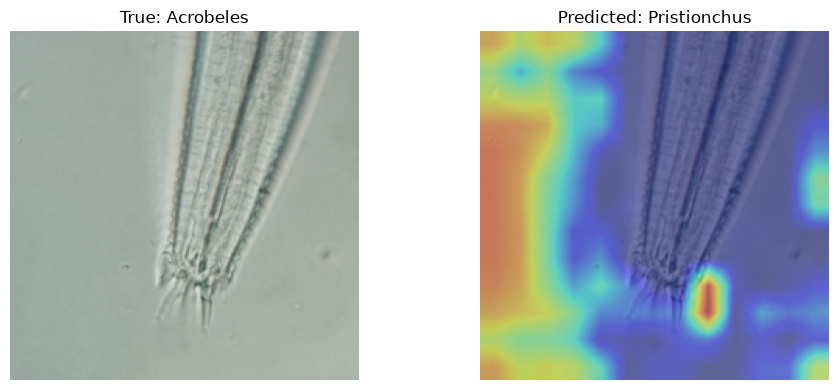

In [9]:
# Set this to the model you want to inspect after it has been trained.
MODEL_FOR_EXPLANATION = 'alexnet'

explain_model = alexnet
checkpoint = torch.load(TRAINED_DIR / f'{MODEL_FOR_EXPLANATION}_nematode.pth', map_location=DEVICE, weights_only=False)
explain_model.load_state_dict(checkpoint['state_dict'])
target_layer = [layer for layer in explain_model.modules() if isinstance(layer, nn.Conv2d)][-1]
saved = {}
def save_features(module, inputs, output):
    saved['activations'] = output
    output.register_hook(lambda gradient: saved.update({'gradients': gradient}))
target_layer.register_forward_hook(save_features)

image, label = val_set[2]
scores = explain_model(image.unsqueeze(0).to(DEVICE))
prediction = scores.argmax(1).item()
explain_model.zero_grad()
scores[0, prediction].backward()

weights = saved['gradients'].mean(dim=(2, 3), keepdim=True)
cam = torch.relu((weights * saved['activations']).sum(1, keepdim=True))
cam = torch.nn.functional.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode='bilinear', align_corners=False)[0, 0]
cam = cam.detach().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

image_np = image.permute(1, 2, 0).numpy() * np.array((.229, .224, .225)) + np.array((.485, .456, .406))
image_np = np.clip(image_np, 0, 1)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(image_np); plt.title(f'True: {classes[label]}'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(image_np); plt.imshow(cam, cmap='jet', alpha=.45); plt.title(f'Predicted: {classes[prediction]}'); plt.axis('off')
plt.tight_layout()